# Exercise 3: Agentic architectures for HydroMT / Wflow

You will run the same kind of hydrological question through agents of increasing complexity. For each one,
ask: *what did the extra structure buy me, and what did it cost?*

| # | Architecture | Pattern (Agentic Overview) |
|---|---|---|
| A0 | Plain LLM + fixed workflow | Deterministic workflow, no agent |
| A1 | Single agent (ReAct) | Dynamic orchestration: single agent |
| A2 | Generator-critic loop | Deterministic workflow: loop / generator-critic |
| A3 | Director + subagents + human-in-the-loop | Subagents (supervisor) + HITL + custom logic |
| A4 | Claude Agent SDK harness + skills | Agent harness + skills (code agent) |
| A4m | Mistral Vibe harness + skills | The same pattern with Mistral's own harness |
| A5 | Router -> {LLM, ReAct, harness} -> human check | Composing harness agents inside a framework |

**Model:** wflow_sbm of the upper Moselle to Epinal (HydroMT build from `hydromt/`), forced with E-OBS for
2019-2020. Agents change parameters through **multipliers** (A0-A3, A5). The code agent (A4) can also write
Python that edits the NetCDF files directly.

Prerequisites:
- the course environment, with `verify_env.py` all OK;
- Julia `Wflow` 1.x;
- API keys in a `.env` file at the repo root or in a parent folder. Never paste keys into this notebook.

## Step 0: Setup
`PROVIDER` picks the model for the LangGraph architectures (A0-A3, A5, your own graph): `"anthropic"` (Claude),
`"mistral"` (Mistral on Azure Foundry, deployment `DEPLOYMENT_MISTRAL_LARGE_4`) or `"azure"` (GPT). Run the same
step with two providers and compare them on the scoreboard.

The harness architectures do **not** use `PROVIDER`: each vendor's model runs in that vendor's own harness, so
A4 is always Claude + Claude Agent SDK and A4m is always Mistral + Mistral Vibe. A5's open-ended step follows
`PROVIDER` the same way (Mistral -> Vibe; Claude, or GPT which has no harness here -> Claude Agent SDK).

Claude auth: with `FOUNDRY_ENDPOINT` + `FOUNDRY_KEY` in `.env`, Claude is called through Azure Foundry
(deployment `DEPLOYMENT_OPUS_55`). Otherwise `ANTHROPIC_API_KEY` is used, or set `HARNESS_AUTH = "login"` to
use your Claude Code login for the Claude harness.

In [6]:
import os
import sys
from pathlib import Path

EXERCISE_DIR = Path.cwd() if (Path.cwd() / "hydroagent").exists() else Path.cwd() / "exercises" / "03_agentic_workflows"
sys.path.insert(0, str(EXERCISE_DIR))

PROVIDER = "anthropic"          # LangGraph architectures only: or "mistral", "azure"
os.environ.setdefault("HARNESS_AUTH", "auto")   # "login" to use the Claude Code login for the Claude harness

from IPython.display import Image, Markdown, display

from hydroagent import config as C
from hydroagent import scoreboard
from hydroagent import twin
from hydroagent import wflow_tools as W
from hydroagent.architectures import registry as R
from hydroagent.notebook_ui import run_with_buttons   # answer agent questions with buttons
from hydroagent.runtime import run_interactive

print("env file:", C.load_env())
print("settings:", C.get_settings(provider=PROVIDER))
for k in R.INFOS:   # what each architecture will actually run on
    print(f"  {k:4s} {R.model_label(k, PROVIDER)}")


def show(ev):
    """Print the agent's trace as it happens. Remove kinds you find noisy ("model" = HydroMT/Wflow console)."""
    if ev.kind in ("llm", "tool_call", "node", "human", "error", "harness", "model"):
        print(f"[{ev.kind}] {ev.title}: {ev.detail[:250]}")


# Stream HydroMT / Wflow console output also when you call the model functions directly (Step 1).
W.LOG_SINK.set(lambda source, line: print(f"  [{source}] {line}"))


def report(out):
    """Show the answer, plots and the cost/time metrics. Every run is also logged to the scoreboard."""
    if out.status == "interrupted":
        q = out.question
        if isinstance(q, dict):  # e.g. plan approval: {"question": ..., "plan": [{"agent", "task"}, ...]}
            steps = [f"{i}. **{s.get('agent', '')}**: {s.get('task', s)}" if isinstance(s, dict) else f"{i}. {s}"
                     for i, s in enumerate(q.get("plan", []), 1)]
            q = "\n".join([q.get("question", ""), ""] + steps)
        display(Markdown(f"### 🙋 The agent asks you\n\n{q}\n\n"
                         "Answer with the buttons below."))
        return
    display(Markdown(out.answer or f"**{out.status}** {out.error}"))
    for p in out.plots:
        display(Image(p))
    u = out.usage
    cost = u.get("cost_usd")
    print(f"LLM calls {u['llm_calls']} | tool calls {u['tool_calls']} | Wflow runs {u['wflow_runs']} | "
          f"tokens {u['total_tokens']:,} (in {u['input_tokens']:,}, out {u['output_tokens']:,}, "
          f"cached {u['cache_read_tokens']:,})")
    print(f"time {u['wall_time_s']} s = LLM {u['llm_s']} + Wflow {u['model_s']} + other {u['other_s']} | "
          f"cost {'$%.4f' % cost if isinstance(cost, (int, float)) else 'n/a'} | runs: {out.run_ids}")
    print(f"scoreboard entry: {out.entry_id}  ->  rate it: scoreboard.rate('{out.entry_id}', 1..5)")

env file: c:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\.env
settings: Settings(provider='anthropic', anthropic_model='claude-opus-5-5', azure_deployment='gpt-5.2', mistral_deployment='mistral-large-4-latest', temperature=0.0, harness_auth='auto')
  a0   claude-opus-5-5 + LangGraph
  a1   claude-opus-5-5 + LangGraph
  a2   claude-opus-5-5 + LangGraph
  a3   claude-opus-5-5 + LangGraph
  a4   claude-opus-5-5 + Claude Agent SDK
  a4m  mistral-large-4-latest + Mistral Vibe
  a5   claude-opus-5-5 + LangGraph (open-ended step: claude-opus-5-5 + Claude Agent SDK)


Build the model (once, about 2 min), start Wflow, and run the baseline. The first Julia start takes about
1-1.5 min. After that, a run takes about 15 s because the Julia process stays alive.

In [7]:
W.prepare_base_model()
baseline = W.ensure_baseline()
print(baseline.status, baseline.runtime_s, "s")
W.summarise_run("baseline", reference="")

done 76.7 s


{'run_id': 'baseline',
 'label': 'baseline',
 'multipliers': {},
 'status': 'done',
 'gauge': '9116044 - Moselle at Epinal (outlet, 1220 km2)',
 'stats_m3s': {'mean': 29.36,
  'max': 284.95,
  'q95_high': 96.84,
  'q10_low': 3.83,
  'date_of_max': '2020-02-04'}}

## Step 1: The tools, without any LLM
Agents are only as good as their tools. These are the functions the agents call. Try them yourself first.

In [9]:
W.list_parameters()[:4]

[{'key': 'ksat_vertical',
  'kind': 'map',
  'unit': 'mm/day',
  'allowed_multiplier': [0.1, 10.0],
  'description': 'Vertical saturated hydraulic conductivity at the soil surface (KsatVer). Lower = less infiltration, more fast runoff.'},
 {'key': 'ksat_decay_f',
  'kind': 'map',
  'unit': '1/mm',
  'allowed_multiplier': [0.3, 3.0],
  'description': 'Exponential decay of KsatVer with depth (f). Higher = Ksat drops faster with depth.'},
 {'key': 'ksat_horizontal_ratio',
  'kind': 'scalar',
  'unit': '-',
  'allowed_multiplier': [0.1, 10.0],
  'description': 'Ratio horizontal/vertical Ksat (KsatHorFrac). Higher = more lateral subsurface flow, smoother hydrograph.'},
 {'key': 'soil_thickness',
  'kind': 'map',
  'unit': 'mm',
  'allowed_multiplier': [0.3, 3.0],
  'description': 'Total soil thickness. Thicker = more storage, lower peaks, more baseflow.'}]

In [10]:
run = W.run_scenario({"ksat_vertical": 0.7}, "ksat -30% (by hand)")
W.summarise_run(run.run_id)

  [wflow] starting Julia + loading Wflow.jl (first time ~1 min) ...
  [wflow] warm-up: compiling Wflow with a 2-day run ...
  [wflow] Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
  [wflow] Info: Wflow version v1.0.4
  [wflow] Info: Initialize model variables for model type sbm.
  [wflow] Info: Cyclic parameters are provided by C:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\staticmaps.nc.
  [wflow] Info: Forcing parameters are provided by C:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\inmaps-eobs-2019-2020.nc.
  [wflow] Info: Set atmosphere_water__precipitation_volume_flux using netCDF variable precip as forcing parameter.
  [wflow] Info: Set atmosphere_air__temperature using netCDF variable temp as forcing parameter.
  [wflow] Info: Set 

{'run_id': '1113-112728-ksat-30-by-hand-fd6f',
 'label': 'ksat -30% (by hand)',
 'multipliers': {'ksat_vertical': 0.7},
 'status': 'done',
 'gauge': '9116044 - Moselle at Epinal (outlet, 1220 km2)',
 'stats_m3s': {'mean': 29.12,
  'max': 313.96,
  'q95_high': 99.33,
  'q10_low': 3.48,
  'date_of_max': '2020-02-04'},
 'pct_change_vs_baseline': {'mean': -0.8,
  'max': 10.2,
  'q95_high': 2.6,
  'q10_low': -9.0}}

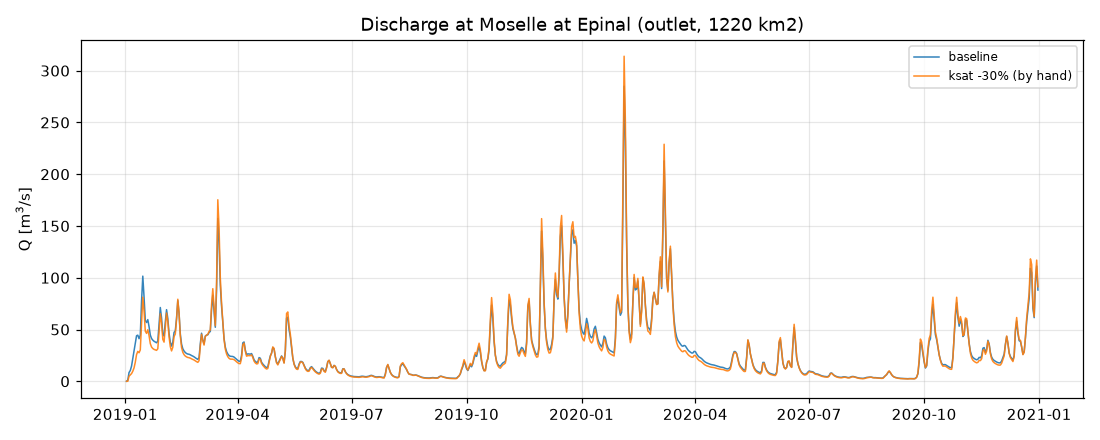

In [6]:
display(Image(str(W.plot_runs(["baseline", run.run_id]))))

## How your question reaches each agent
Every step below has a `QUESTION = "..."` line: edit it to ask your own. All architectures start the same way:
`session.start(QUESTION)` (or `run_interactive(session, QUESTION)`, which does the same) puts your question
into the graph's starting state twice:

- `query`: the plain question text, for steps that write their own prompt around it;
- `messages`: a chat history that starts with your question, for agents that converse.

What differs is **who sees it**:

| | Who reads your question |
|---|---|
| **A0** | `interpret` (as part of its prompt) and `report` (with the Wflow results) |
| **A1** | the ReAct agent, as the first chat message |
| **A2** | the generator, every round. The critic sees only the scores, not your question |
| **A3** | `classify`. Your clarifications are appended to it. The modeller subagent gets a task written by the plan, **not** your question |
| **A4** | Claude, as the task (on top of a system prompt with the model paths) |
| **A5** | the router, then the chosen branch (prompt, chat message or harness task) |
| **your graph** | agent nodes get the chat history. Plain-LLM and critic nodes get a transcript. A harness node gets `{query}` |

When an agent pauses to ask *you* something, buttons appear in the cell (`run_with_buttons`). Your click calls
`session.resume(answer)`, which sends the answer back into the paused step. The run continues from there; it
does not start over.

## Step 2: A0, plain LLM + fixed workflow

![A0 architecture](docs/figures/a0.png)

The LLM only translates the question into multipliers and writes the report. Code fixes the order of steps.

[llm] LLM [interpret]: {"label":"ksat -30%","multipliers":[{"parameter":"ksat_vertical","multiplier":0.7}],"rationale":"Soil permeability is represented by the vertical saturated hydraulic conductivity (KsatVer), so a 30% reduction maps directly to ksat_vertical x0.7, whic
[node] node: interpret: {"label":"ksat -30%","multipliers":[{"parameter":"ksat_vertical","multiplier":0.7}],"rationale":"Soil permeability is represented by the vertical saturated hydraulic conductivity (KsatVer), so a 30% reduction maps directly to ksat_vertical x0.7, whic
[model] wflow: Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
[model] wflow: Info: Wflow version v1.0.4
[model] wflow: Info: Initialize model variables for model type sbm.
[model] wflow: Info: Cyclic parameters are provided by C:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\staticmaps.nc.
[

**Peaks rise by about 10% and low flows fall by about 9% at Epinal (GRDC 9116044)**

Based on run `1113-113110-ksat-30-e606` (ksat_vertical ×0.7) compared with the baseline. The baseline run_id was not included in the result I received, so baseline values below are back-calculated from the reported % changes.

| Statistic (m³/s) | Baseline (derived) | ksat −30% | Change |
|---|---|---|---|
| Max (on 2020-02-04) | ~284.9 | 313.96 | **+10.2%** |
| Q95 (high flows) | ~96.8 | 99.33 | +2.6% |
| Mean | ~29.4 | 29.12 | −0.8% |
| Q10 (low flows) | ~3.82 | 3.48 | **−9.0%** |

- **Peak flows:** the annual peak goes up by about 29 m³/s. Moderately high flows (Q95) change much less, so the effect is concentrated on the largest event.
- **Low flows:** Q10 drops by about 0.34 m³/s, a meaningful relative loss of baseflow.
- **Volume:** the mean barely changes (−0.8%), so total water volume is nearly unchanged; mostly the timing shifts.

**Explanation:** lower KsatVer reduces infiltration and recharge, so more water leaves as fast runoff (higher peaks) and less as slow subsurface flow (lower baseflow).

**Caveats:**
- This is a single 2-year run (2019–2020, excluding the 3-month spin-up), and the peak change rests mainly on one event (Feb 2020).
- Treat the +10% peak change as indicative, not robust.

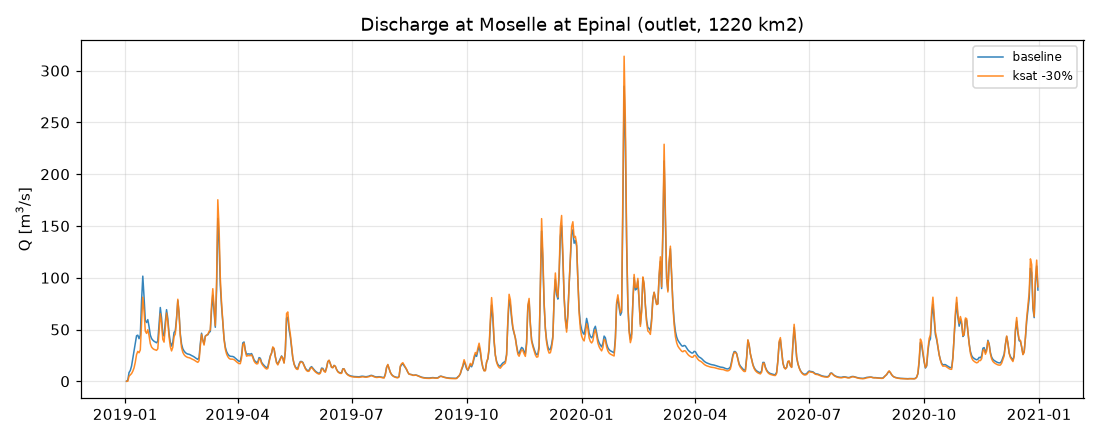

LLM calls 2 | tool calls 0 | Wflow runs 1 | tokens 2,999 (in 2,140, out 859, cached 0)
time 32.3 s = LLM 10.1 + Wflow 10.1 + other 12.1 | cost $0.0257 | runs: ['1113-113110-ksat-30-e606']
scoreboard entry: 8a71aa36  ->  rate it: scoreboard.rate('8a71aa36', 1..5)


In [11]:
QUESTION = "What happens to peak and low flows at Epinal if soils become 30% less permeable?"   # edit me
out = run_interactive(R.create_session("a0", provider=PROVIDER, on_event=show), QUESTION)
report(out)

## Step 3: A1, single agent (ReAct)

![A1 architecture](docs/figures/a1.png)

One LLM with tools in a loop. **Customise it:** change the system prompt or remove a tool set, and see how the
behaviour changes. Try a question that needs *two* scenarios, for example comparing +20% and -20% soil thickness.

In [ ]:
from hydroagent.architectures import a1_react
from hydroagent.architectures.common import make_session

MY_PROMPT = a1_react.SYSTEM_PROMPT          # edit me
MY_TOOLSETS = ("parameters", "simulation", "analysis")   # try removing "analysis" or "simulation"

session = make_session("a1", a1_react.build, provider=PROVIDER, on_event=show,
                       system_prompt=MY_PROMPT, toolsets=MY_TOOLSETS)
QUESTION = "Compare +20% and -20% soil thickness: which affects low flows at Epinal more?"   # edit me
out = run_interactive(session, QUESTION)
report(out)

KeyError: 'a'

## Step 4: A2, generator-critic loop (calibration)

![A2 architecture](docs/figures/a2.png)

There are no observed discharge series in this repo, so we use a **twin experiment**. A hidden "truth" run
made with secret multipliers plays the role of observations, and the loop tries to recover it.
**Knobs:** `max_iter`, `target_kge`, `critic="llm"` vs `"rule"`. Is the LLM critic worth its tokens?

[llm] LLM [generator]: {"reasoning":"No runs yet, so I am starting from the default parameters (all x1.0) to get a baseline KGE, r, alpha and beta at Epinal before adjusting anything.","multipliers":[{"parameter":"ksat_vertical","multiplier":1.0},{"parameter":"soil_thickne
[node] node: generator: {'ksat_vertical': 1.0, 'soil_thickness': 1.0, 'ksat_horizontal_ratio': 1.0} | No runs yet, so I am starting from the default parameters (all x1.0) to get a baseline KGE, r, alpha and beta at Epinal before adjusting anything.
[model] wflow: Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
[model] wflow: Info: Wflow version v1.0.4
[model] wflow: Info: Initialize model variables for model type sbm.
[model] wflow: Info: Cyclic parameters are provided by C:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\staticmaps.nc.
[model] wflow: Info: Forcin

**Calibration summary: Moselle at Epinal, GRDC 9116044 (2019–2020, spin-up excluded). No run_ids were supplied, so this is based on iterations 1–3.**

1. **Best set (iter 3):** ksat_vertical ×1.4, soil_thickness ×1.5, ksat_horizontal_ratio ×1.0. Scores: KGE 0.973, NSE 0.997, r 0.999, α 1.003, β 1.027.
2. **KGE progression:** 0.860 (iter 1, default) → 0.942 (iter 2) → 0.973 (iter 3). Most of the gain came from α: excess variability fell from 1.137 to 1.003 as infiltration and soil storage increased.
3. **Persistent bias:** pbias barely moved (3.0% → 2.7%). These parameters cannot fix volume. Check precipitation (E-OBS) or evapotranspiration parameters instead.
4. **Equifinality:** ksat_vertical and soil_thickness were always raised together, so their effects cannot be separated. Other combinations, such as higher soil_thickness with lower ksat, may score as well.
5. **Under-explored space:** ksat_horizontal_ratio was never varied. The optimum lies at the edge of the tested range, so the true best may be beyond ×1.4/×1.5.
6. **No independent validation:** calibration and evaluation used the same 2 years, with no split-sample test. Expect lower skill outside 2019–2020.
7. **Suspiciously high scores:** NSE 0.997 and r 0.999 are unusually high for daily wflow_sbm. Verify that the observations are real GRDC data, not a synthetic or reference run, before trusting this set.
8. **Next steps:**
   - Sample the parameters independently, for example with a Latin hypercube, and include ksat_horizontal_ratio.
   - Validate on a separate period.
   - Report the full range of behavioural parameter sets, not just a single best set.

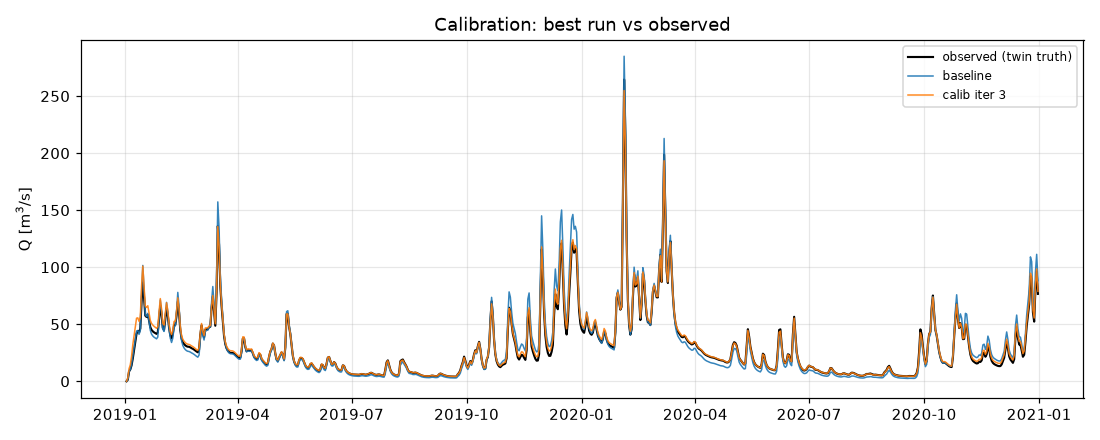

LLM calls 6 | tool calls 0 | Wflow runs 3 | tokens 9,876 (in 6,812, out 3,064, cached 0)
time 66.2 s = LLM 34.4 + Wflow 31.5 + other 0.2 | cost $0.0885 | runs: ['1113-114502-calib-iter-1-9609', '1113-114525-calib-iter-2-41e0', '1113-114546-calib-iter-3-b912']
scoreboard entry: de790032  ->  rate it: scoreboard.rate('de790032', 1..5)


In [16]:
twin.ensure_truth()
QUESTION = ("Calibrate ksat_vertical, soil_thickness and ksat_horizontal_ratio so the Epinal discharge matches "
            "observations (target KGE 0.95).")   # edit me
out = run_interactive(R.create_session("a2", provider=PROVIDER, on_event=show, max_iter=4, critic="llm"), QUESTION)
report(out)

In [17]:
print("the truth was:", twin.reveal_truth())   # debrief: equifinality?

the truth was: {'ksat_vertical': 0.4, 'soil_thickness': 1.6, 'ksat_horizontal_ratio': 3.0}


## Step 5: A3, Director with subagents and human-in-the-loop

![A3 architecture](docs/figures/a3.png)

This follows the Director pattern:
- an allow-list of scenario types;
- clarification questions when inputs are missing;
- plan approval before any compute is spent;
- Modeller and Analyst subagents, with retries and escalation.

The agent pauses to ask you questions. Answer with the **buttons** that appear in the cell output:
a text box + **Send** for open questions (try `-30`), **Approve / Reject** for the plan. After each click the
trace and result appear under the buttons. Try an out-of-scope request too.

In [18]:
QUESTION = "What if the soils in the Moselle become less permeable?"   # edit me (no % on purpose: it will ask)
a3 = R.create_session("a3", provider=PROVIDER, on_event=show)
a3_run = run_with_buttons(a3, QUESTION, report)   # a3_run["out"] holds the latest outcome

[llm] LLM [classify]: {"scenario":"soil_permeability","change_pct":null,"gauge":"9116044","reason":"The user asks about reduced soil permeability in the Moselle catchment without specifying a magnitude, which maps to the soil_permeability scenario at the default Epinal ga
[node] node: classify: {"scenario":"soil_permeability","change_pct":null,"gauge":"9116044","reason":"The user asks about reduced soil permeability in the Moselle catchment without specifying a magnitude, which maps to the soil_permeability scenario at the default Epinal ga
[human] waiting for human: Scenario 'soil_permeability' recognised. By how many percent should 'ksat_vertical' change? (e.g. -30 for 30% lower)


### 🙋 The agent asks you

Scenario 'soil_permeability' recognised. By how many percent should 'ksat_vertical' change? (e.g. -30 for 30% lower)

Answer with the buttons below.

## Step 6: A4, Claude Agent SDK harness + skills (code agent)

![A4 architecture](docs/figures/a4.png)

> **Security: run Step 6 in the course web app.** A4, A4m and the skills lab let the LLM write and run its own
> code. On your laptop that code would run with your rights (your files, network and keys), so here they run
> only in the sandboxed Streamlit app (URL and password given in class). On your machine the cells below stop
> with *"Code-writing agents are disabled on this machine"*. Read them to see how the harness is called, then
> run the same task on the app's A4 / A4m pages and its skills lab.

The harness writes and runs its own Python on `staticmaps.nc` / `output.nc`. It works in a sandboxed
workspace and runs Wflow through an MCP tool.

It loads **skills** on demand:
- `wflow-toml`
- `netcdf-analysis`
- `hydrology-env` (the repo's environment skill)

Watch for `tool: Skill` in the trace.

In [19]:
from hydroagent.harness.claude_runner import available_skills, run_harness

[(s["name"], s["description"][:80]) for s in available_skills()]

[('netcdf-analysis',
  'Read, analyse and modify Wflow NetCDF files (staticmaps.nc parameters, output.nc'),
 ('wflow-toml',
  'How Wflow.jl 1.x TOML files are structured and how to change parameters safely ('),
 ('hydrology-env',
  'Installs and verifies the hydrology training stack (Git, uv >= 0.13.6, Julia, Py')]

[harness] session start: model=claude-opus-5-5 skills=['hydrology-env', 'netcdf-analysis', 'wflow-toml', 'deep-research', 'dataviz', 'update-config', 'verify', 'debug', 'code-review', 'simplify', 'batch', 'fewer-permission-prompts', 'doctor', 'loop', 'claude-api', 'workflow-
[tool_call] tool: Skill: {"skill": "netcdf-analysis"}
[tool_call] tool: ToolSearch: {"query": "select:mcp__hydro__run_wflow_scenario,mcp__hydro__get_run_summary", "max_results": 2}
[tool_call] tool: Write: {"file_path": "C:/Users/deng_jg/work/16centralized_agents/hydrology_user_day_training/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/harness/1113-120304-a92d/make_maps.py", "content": "import xarray as xr, numpy as
[tool_call] tool: Bash: {"command": "cd C:/Users/deng_jg/work/16centralized_agents/hydrology_user_day_training/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/harness/1113-120304-a92d && \"c:/Users/deng_jg/work/16centralized_agents/

I halved soil permeability (`soil_ksat_vertical`) in the Fresse-sur-Moselle sub-catchment only and ran the model. Annual-maximum discharge rises by about 21–32 % at Fresse-sur-Moselle and by about 2 % at Epinal.

**What changed:** the 124 grid cells where `subcatchment_grdc == 9116039`. Their mean permeability went from 1559 to 780 mm/day. Every cell outside that sub-catchment is unchanged.

**Run_ids compared:** `baseline` and `1113-120339-fresse-ksat-half-bd26`

**Annual-maximum discharge (2019 counts from 1 April, after the spin-up period):**

| Gauge | Year | Baseline | Halved permeability | Change |
|---|---|---|---|---|
| Fresse-sur-Moselle (9116039) | 2019 | 7.84 m³/s (25 Dec) | 9.46 m³/s (24 Dec) | +1.62 m³/s (+20.7 %) |
| Fresse-sur-Moselle (9116039) | 2020 | 11.97 m³/s (4 Feb) | 15.85 m³/s (4 Feb) | +3.88 m³/s (+32.4 %) |
| Epinal (9116044) | 2019 | 150.14 m³/s (16 Dec) | 152.97 m³/s (16 Dec) | +2.83 m³/s (+1.9 %) |
| Epinal (9116044) | 2020 | 284.95 m³/s (4 Feb) | 291.16 m³/s (4 Feb) | +6.21 m³/s (+2.2 %) |

- **Fresse-sur-Moselle:** lower permeability means less water soaks into the soil and more runs off quickly, so floods get much bigger.
- **Epinal:** the effect is mostly diluted by the larger catchment. Over the whole period, Epinal's mean flow changes by −0.1 % and its low flow (the flow exceeded 90 % of the time) by −0.7 %, so slightly less water reaches the river later through the soil.
- **Puzzle:** in absolute terms, the Epinal peak rises more than the Fresse peak (+6.2 vs +3.9 m³/s in 2020). Both peaks fall on 4 February 2020, so my guess is that the faster runoff from Fresse lines up better with the flood arriving from the rest of the catchment. I haven't checked this.

**Files** (all in the workspace `.../output/harness/1113-120304-a92d/`):
- Figure: `annual_max_fresse_ksat_half.png` — daily discharge for both runs and annual-maximum bars with % change, for both gauges.
- Edited parameter file: `staticmaps_fresse_ksat05.nc`
- Scripts: `make_maps.py`, `compare.py`

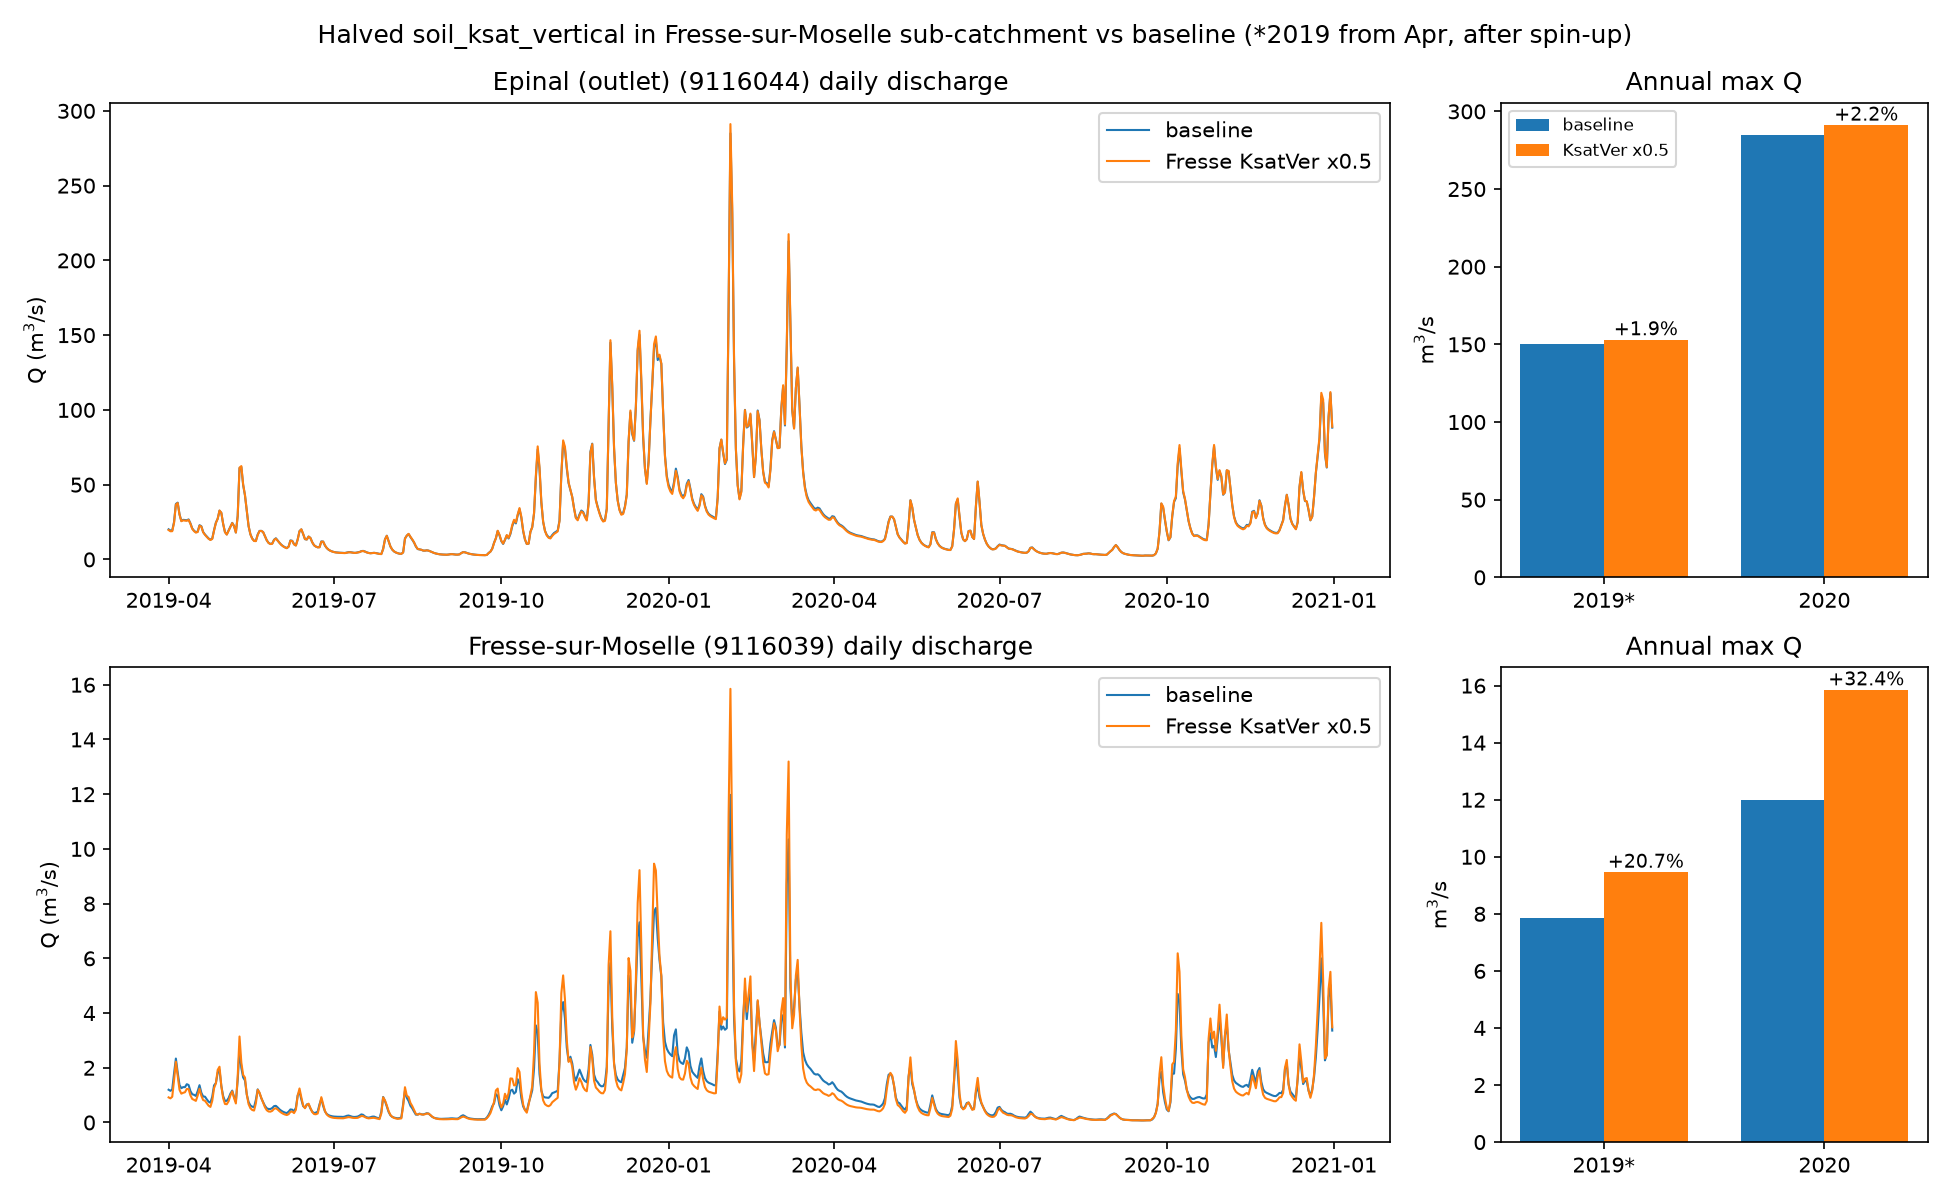

LLM calls 7 | tool calls 7 | Wflow runs 1 | tokens 201,047 (in 16, out 3,914, cached 166,216)
time 72.6 s = LLM 37.9 + Wflow 10.1 + other 24.6 | cost $0.2661 | runs: ['1113-120339-fresse-ksat-half-bd26']
scoreboard entry: 4b8efd9b  ->  rate it: scoreboard.rate('4b8efd9b', 1..5)
skills loaded: ['netcdf-analysis'] | workspace: C:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\exercises\02_agentic_workflows\output\harness\1113-120304-a92d


In [20]:
HARNESS_QUESTION = ("Halve the soil permeability (soil_ksat_vertical) only in the Fresse-sur-Moselle sub-catchment "
                    "(GRDC 9116039), run the model, and compare the annual-maximum discharge at Epinal and at "
                    "Fresse-sur-Moselle with the baseline. Make one figure.")   # edit me (also used by A4m below)
out_a4 = R.create_session("a4", on_event=show).start(HARNESS_QUESTION)
report(out_a4)
print("skills loaded:", out_a4.state.get("skills_loaded"), "| workspace:", out_a4.state.get("workspace"))

### A4m: the same task with Mistral Vibe

![A4m architecture](docs/figures/a4m.png)

Mistral's own coding agent, **Mistral Vibe**, with your Mistral deployment on Azure Foundry. It gets the same
workspace layout, the same skills and the same Wflow tools as A4, so this is a like-for-like comparison of two
harnesses and two models. Install Vibe once: `uv tool install mistral-vibe`.

Compare the two outputs (and the scoreboard below): did both load a skill? Same numbers? Tokens, time, cost?
Rate both answers with `scoreboard.rate(...)`.

In [ ]:
out_a4m = R.create_session("a4m", on_event=show).start(HARNESS_QUESTION)
report(out_a4m)
print("skills loaded:", out_a4m.state.get("skills_loaded"), "| workspace:", out_a4m.state.get("workspace"))

### Write your own skill
Edit the cell below, then run the harness on a task that needs it. Did the agent load it (`skills loaded`)?
Does it help compared with a run *without* the skill (`skills=[...]` excluding it)?
Template: `skills/_template/SKILL.md`.

In [14]:
SKILL_NAME = "flow-duration-curve"
SKILL_MD = """---
name: flow-duration-curve
description: Compute and plot flow-duration curves and exceedance flows (Q10, Q50, Q90, Q95) from Wflow output.csv at a gauge. Use for low-flow / drought or flow-regime questions.
---

# Flow-duration curve

1. Read `<run>/output/output.csv`, column `river_q_<gauge>`; drop dates before 2019-04-01 (spin-up).
2. Sort discharge descending; exceedance probability p = rank / (n + 1).
3. Qx = discharge exceeded x% of the time (Q90 = low flow, Q10 = high flow).
4. Plot with log y-axis, x = exceedance [%]; one line per run; save PNG in the workspace.
5. Report a table of Q10, Q50, Q90, Q95 per run and the % change vs baseline.
"""
d = EXERCISE_DIR / "skills" / SKILL_NAME
d.mkdir(parents=True, exist_ok=True)
(d / "SKILL.md").write_text(SKILL_MD, encoding="utf-8")

r = run_harness("Make flow-duration curves at Epinal for the baseline and the 'ksat -30% (by hand)' run, and report "
                "Q10, Q50, Q90 for both.", on_event=show)
display(Markdown(r.answer or r.error))
print("skills loaded:", r.skills_loaded, "| usage:", r.usage)

[harness] session start: model=claude-opus-5-5 skills=['flow-duration-curve', 'hydrology-env', 'jude-styles', 'netcdf-analysis', 'wflow-toml', 'deep-research', 'dataviz', 'update-config', 'verify', 'debug', 'code-review', 'simplify', 'batch', 'fewer-permission-prompts', 'doc
[tool_call] tool: Skill: {"skill": "flow-duration-curve"}
[tool_call] tool: Skill: {"skill": "jude-styles"}
[tool_call] tool: Bash: {"command": "cd \"C:/Users/king_je/OneDrive - Stichting Deltares/Projects/LLM_general/DSD_agentic_course/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/runs\"; ls; for d in */; do echo \"== $d\"; ls \"$d\"; cat \"$
[tool_call] tool: Bash: {"command": "cd \"C:/Users/king_je/OneDrive - Stichting Deltares/Projects/LLM_general/DSD_agentic_course/LLMs-Agentic-Workflows-in-Hydrology-Training/exercises/02_agentic_workflows/output/runs\"; ls -d *by-hand*; for d in *by-hand*; do ls $d; ls $d/o
[tool_call] tool: Bash: {"command": "cd \"C:/Users/king_je/OneDriv

I made flow-duration curves for both runs at Epinal (gauge `river_q_9116044`, GRDC 9116044). I left out the spin-up, so they cover 2019-04-01 to 2020-12-31 (641 days).

| Run | run_id | Q10 [m³/s] | Q50 [m³/s] | Q90 [m³/s] |
|---|---|---|---|---|
| Baseline | `baseline` | 73.70 | 18.44 | 3.82 |
| ksat −30% (by hand) | `1110-133857-ksat-30-by-hand-9965` | 74.21 (+0.7%) | 17.39 (−5.7%) | 3.45 (−9.7%) |

Q95 went from 3.19 to 2.88 m³/s (−9.5%).

Cutting vertical ksat by 30% (`ksat_vertical` × 0.7) leaves high flows almost unchanged, with Q10 up slightly. Median flow drops by about 6% and low flows by about 10%. Less water soaks into the soil, so there is less baseflow to keep the river going in dry periods.

There are 8 runs named "ksat −30% (by hand)", made between 2026-11-09 and 2026-11-10. They all have the same settings and give exactly the same `output.csv`, so I used the latest one; any of the others would give the same numbers.

Files are in `exercises/02_agentic_workflows/output/harness/1110-134840-02c4/`:
- **Figure:** `fdc_epinal_baseline_vs_ksat30.png` (log y-axis)
- **Table:** `fdc_epinal_table.csv`
- **Script:** `fdc.py`

skills loaded: ['flow-duration-curve', 'jude-styles'] | usage: {'model': 'anthropic:claude-opus-5-5', 'llm_calls': 7, 'tool_calls': 8, 'wflow_runs': 0, 'input_tokens': 14, 'output_tokens': 2910, 'cache_read_tokens': 200143, 'cache_write_tokens': 15363, 'total_tokens': 218430, 'wall_time_s': 57.7, 'llm_s': 27.6, 'model_s': 0.0, 'other_s': 30.1, 'julia_startup_s': 0.0, 'cost_usd': 0.1751, 'cost_source': 'pricing.yml', 'by_node': {'claude_harness': {'llm_calls': 7, 'input_tokens': 14, 'output_tokens': 2910, 'cache_read_tokens': 200143, 'llm_s': 27.64}}}


## Step 7: A5, composed router

![A5 architecture](docs/figures/a5.png)

Try a knowledge question, a uniform parameter scenario, and an open-ended code task. Which route does each take?
What does each cost? The open-ended route runs `PROVIDER`'s own harness (Mistral -> Vibe, otherwise Claude).

On your laptop the open-ended route stops with the "disabled" message (see Step 6); the other routes run
locally. Try an open-ended question on the web app's A5 page.

In [15]:
QUESTIONS = [   # edit me: each question gets its own session; watch which route the router picks
    "What does the KsatHorFrac parameter do in wflow_sbm?",                  # expect: simple_answer
    "Increase river roughness by 50%: how does the Epinal peak change?",     # expect: parameter_scenario
    # "Halve soil_ksat_vertical only in sub-catchment 9116039 and compare annual maxima",  # open_ended_code (slow)
]
for q in QUESTIONS:
    run_with_buttons(R.create_session("a5", provider=PROVIDER, on_event=show), q, report)  # buttons if unsure

[llm] LLM [route]: {"route":"simple_answer","confidence":0.95,"reason":"This is a knowledge question about what the KsatHorFrac parameter means in wflow_sbm. It is the multiplication factor that converts vertical saturated hydraulic conductivity into horizontal (latera
[node] node: route: {"route":"simple_answer","confidence":0.95,"reason":"This is a knowledge question about what the KsatHorFrac parameter means in wflow_sbm. It is the multiplication factor that converts vertical saturated hydraulic conductivity into horizontal (latera
[llm] LLM [simple_answer]: # KsatHorFrac in wflow_sbm

**What it is.** KsatHorFrac is a dimensionless multiplier that converts vertical saturated hydraulic conductivity into horizontal (lateral) conductivity. It controls lateral subsurface flow:

- kh₀ = KsatHorFrac × KsatVer₀
[node] node: simple_answer: 
[node] node: human_check: confidence above threshold - no human check


# KsatHorFrac in wflow_sbm

**What it is.** KsatHorFrac is a dimensionless multiplier that converts vertical saturated hydraulic conductivity into horizontal (lateral) conductivity. It controls lateral subsurface flow:

- kh₀ = KsatHorFrac × KsatVer₀ (at the soil surface)
- kh(z) = kh₀ · e^(−f·z), which decays with depth using the same f as KsatVer in the default exponential profile.
- Lateral subsurface flow is routed with a kinematic wave between cells. The flux is roughly kh × saturated thickness × local slope × flow width.

**Why it exists.** It lumps several effects that make effective lateral conductivity much larger than point or vertical Ksat:

- soil anisotropy
- macropores and preferential flow paths
- scale effects (1 km cells versus pedotransfer-function Ksat)

Typical values are about 1–1000. HydroMT's default is a uniform 100. Newer HydroMT-wflow versions can also supply a regionalized map (Bouaziz et al., 2022).

**Hydrological effect if you increase it:**

- faster lateral drainage of the saturated store toward the river
- deeper water tables and less saturation-excess overland flow
- lower, broader peaks
- higher, more sustained baseflow, with drainage shifted from storm events toward recessions

Decreasing it does the opposite: wetter hillslopes, more saturation-excess runoff, flashier peaks, and faster low-flow decline.

**In practice.** It is one of the most sensitive calibration parameters for wflow_sbm. It interacts strongly with ksat_vertical and f. A ksat_vertical × 0.7 scenario also lowers horizontal conductivity by 30% unless KsatHorFrac is compensated. In the TOML it is `lateral.subsurface.ksathorfrac` (Wflow.jl v0.x). In v1.x it is the standard name `subsurface_water__horizontal-to-vertical_saturated_hydraulic_conductivity_ratio`.

*Basis: model documentation and general knowledge only. No run_ids were used; I have not quantified sensitivity for the Moselle/Epinal model.*

LLM calls 2 | tool calls 0 | Wflow runs 0 | tokens 2,300 (in 954, out 1,346, cached 0)
time 15.1 s = LLM 15.0 + Wflow 0.0 + other 0.0 | cost $0.0307 | runs: []
scoreboard entry: 8e533e81  ->  rate it: scoreboard.rate('8e533e81', 1..5)
[llm] LLM [route]: {"route":"parameter_scenario","confidence":0.9,"reason":"The request is a uniform parameter multiplier: river Manning's n (river roughness) times 1.5. The question is then answered with a standard statistic, the peak discharge at the Epinal gauge, co
[node] node: route: {"route":"parameter_scenario","confidence":0.9,"reason":"The request is a uniform parameter multiplier: river Manning's n (river roughness) times 1.5. The question is then answered with a standard statistic, the peak discharge at the Epinal gauge, co
[llm] LLM [model]: -> wants to call: list_parameters({})
[tool_call] tool: list_parameters: {}
[llm] LLM [model]: -> wants to call: run_scenario({"multipliers": {"river_manning_n": 1.5}, "label": "river n +50%"})
[tool_call]

Making the river 50% rougher lowers the Epinal peak only a little, by about **2%**.

I ran this by multiplying `river_manning_n` by 1.5 (run **1110-134957-river-n-50-69c8**) and compared it with the automatic baseline run.

| Statistic at Epinal (GRDC 9116044) | River roughness +50% | Change vs baseline |
|---|---|---|
| Peak flow (2020-02-04) | 279.2 m³/s | **−2.0%** (about −5.7 m³/s; baseline ≈ 284.9 m³/s, worked out from the % change) |
| Q95 (high flows) | 97.0 m³/s | +0.1% |
| Mean flow | 29.35 m³/s | 0.0% |
| Q10 (low flows) | 3.82 m³/s | −0.1% |

**Why:** a rougher channel slows the flood wave and spreads it out a little, but it doesn't change how much water there is. The mean and low flows stay the same, and only the highest daily peak drops. The effect is small because the rivers above Epinal are short (1220 km²), so water spends little time in them. The peak depends much more on how fast water runs off the hillsides. Also, the model saves daily values, which hides much of the flattening that happens within a single day.

If the goal is lower flood peaks, changing the soil and runoff parameters (`ksat_vertical`, `soil_thickness`, `land_manning_n`) would likely have a much bigger effect than changing channel roughness.

LLM calls 4 | tool calls 2 | Wflow runs 1 | tokens 9,354 (in 8,562, out 792, cached 0)
time 26.8 s = LLM 10.2 + Wflow 16.6 + other 0.1 | cost $0.0501 | runs: ['1110-134957-river-n-50-69c8']
scoreboard entry: 8f43d0ef  ->  rate it: scoreboard.rate('8f43d0ef', 1..5)


## Step 8: Build your own graph (JSON)
This is the same spec the Streamlit canvas produces.

Node types:
- `llm_agent`
- `plain_llm`
- `tool_step`
- `critic` (edges labelled `approved` / `revise`)
- `router` (edges labelled with a description of when to take them)
- `human`
- `claude_harness` (web app only: on your laptop it stops with the "disabled" message, see Step 6)

valid
[llm] LLM [model]: -> wants to call: list_parameters({})
[tool_call] tool: list_parameters: {}
[llm] LLM [model]: -> wants to call: run_scenario({"multipliers": {"crop_factor": 1.5}, "label": "crop factor +50%"})
[tool_call] tool: run_scenario: {'multipliers': {'crop_factor': 1.5}, 'label': 'crop factor +50%'}
[model] wflow: Warning: 'wflow_version' is not recognized as a valid field of the [input] section in the TOML, this will be ignored.
[model] wflow: Info: Wflow version v1.0.4
[model] wflow: Info: Initialize model variables for model type sbm.
[model] wflow: Info: Cyclic parameters are provided by C:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\staticmaps.nc.
[model] wflow: Info: Forcing parameters are provided by C:\Users\deng_jg\work\16centralized_agents\hydrology_user_day_training\LLMs-Agentic-Workflows-in-Hydrology-Training\wflow_moselle_epinal\inmaps-eobs-2019-2020.nc.
[model] wflow

**Note for water management: Moselle at Epinal, crop factor +50% (2019–2020)**

1. Higher evapotranspiration (crop factor +50%) cuts low flows at Epinal by about 37%, from about 3.8 to 2.4 m³/s (q10). Mean flow falls by about 15%, from about 29.3 to 25.0 m³/s.
2. Flood peaks barely change (−3%, about 277 m³/s on 4 Feb 2020), so the main risk is summer drought and water availability, not flooding.
3. Low flows react about 2.5 times more strongly than mean flow, so low-flow thresholds and abstraction limits should account for warmer, higher-evapotranspiration conditions.

*Based on run `1113-121213-crop-factor-50-e51d` compared with the base model run. Baseline values are back-calculated from % changes because no baseline run_id was returned.*

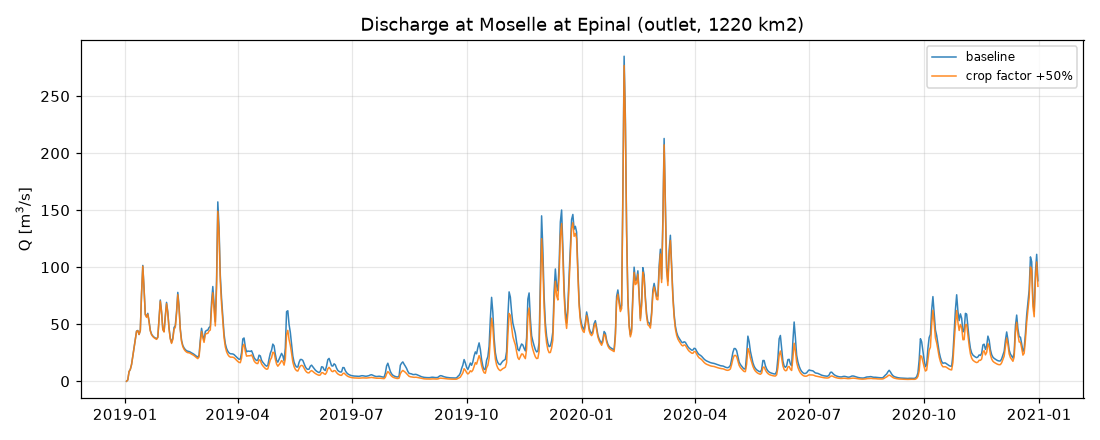

LLM calls 5 | tool calls 2 | Wflow runs 1 | tokens 9,366 (in 7,971, out 1,395, cached 0)
time 26.9 s = LLM 17.0 + Wflow 9.7 + other 0.2 | cost $0.0598 | runs: ['1113-121213-crop-factor-50-e51d']
scoreboard entry: 303e0861  ->  rate it: scoreboard.rate('303e0861', 1..5)


{'out': Outcome(status='done', answer='**Note for water management: Moselle at Epinal, crop factor +50% (2019–2020)**\n\n1. Higher evapotranspiration (crop factor +50%) cuts low flows at Epinal by about 37%, from about 3.8 to 2.4 m³/s (q10). Mean flow falls by about 15%, from about 29.3 to 25.0 m³/s.\n2. Flood peaks barely change (−3%, about 277 m³/s on 4 Feb 2020), so the main risk is summer drought and water availability, not flooding.\n3. Low flows react about 2.5 times more strongly than mean flow, so low-flow thresholds and abstraction limits should account for warmer, higher-evapotranspiration conditions.\n\n*Based on run `1113-121213-crop-factor-50-e51d` compared with the base model run. Baseline values are back-calculated from % changes because no baseline run_id was returned.*', question=None, run_ids=['1113-121213-crop-factor-50-e51d'], plots=['C:\\Users\\deng_jg\\work\\16centralized_agents\\hydrology_user_day_training\\LLMs-Agentic-Workflows-in-Hydrology-Training\\exercises\

In [21]:
from hydroagent.builder.compile import make_custom_session, validate

my_graph = {
    "name": "my_agent",
    "nodes": [
        {"id": "start", "type": "start"},
        {"id": "modeller", "type": "llm_agent", "config": {"toolsets": ["parameters", "simulation"],
                                                         "system_prompt": "Run the scenario(s) needed. Be brief."}},
        {"id": "plot", "type": "tool_step", "config": {"action": "plot_all_runs"}},
        {"id": "critic", "type": "critic", "config": {"criteria": "Gives % change for peak AND low flow with run_ids.",
                                                    "max_loops": 1}},
        {"id": "writer", "type": "plain_llm", "config": {"instruction": "Write a 3-line note for a water manager."}},
        {"id": "end", "type": "end"},
    ],
    "edges": [
        {"source": "start", "target": "modeller"}, {"source": "modeller", "target": "plot"},
        {"source": "plot", "target": "critic"}, {"source": "critic", "target": "modeller", "label": "revise"},
        {"source": "critic", "target": "writer", "label": "approved"}, {"source": "writer", "target": "end"},
    ],
}
print(validate(my_graph) or "valid")
QUESTION = "How do low flows at Epinal respond to a 50% higher crop factor?"   # edit me
run_with_buttons(make_custom_session(my_graph, provider=PROVIDER, on_event=show), QUESTION, report)

## Debrief: which architecture strikes the right balance?
Every run above was logged to the **scoreboard** (`output/scoreboard.jsonl`) with its tokens, time split
(LLM vs Wflow vs other) and estimated cost (`pricing.yml`). Only *you* can judge the quality: rate each
answer from 1 to 5 with `scoreboard.rate(entry_id, score)`, using the entry ids printed by `report()`.
Then compare. A fair comparison uses the same question for every architecture, ideally repeated 2-3 times,
because agents are not deterministic.

In [22]:
# scoreboard.rate("<entry id>", 4)          # rate your answers first
sb = scoreboard.load()
display(sb[["id", "arch", "status", "quality", "total_tokens", "wall_time_s", "llm_s", "model_s", "cost_usd",
            "question"]].tail(20))
summary = scoreboard.summary(sb)
summary["tokens_per_quality_pt"] = (summary["total_tokens"] / summary["quality"]).round(0)
summary

,id,arch,status,quality,total_tokens,wall_time_s,llm_s,model_s,cost_usd,question
19,bb1f06aa,a4,done,NaN,199845,80.3,36.4,15.0,0.2579,Halve the soil permeability (soil_ksat_vertica...
20,997aed9a,a4,done,NaN,224481,76.5,41.2,13.6,0.2725,Halve the soil permeability (soil_ksat_vertica...
21,7c1f43ef,a5,done,NaN,2417,15.7,15.6,0.0,0.0329,What is the difference between KsatVer and Ksa...
22,91b911e2,a5,done,NaN,1776,10.9,10.8,0.0,0.0209,what can you do?
23,003c55ed,a5,done,NaN,3022,23.6,23.5,0.0,0.0455,how to calibrate wflow_sbm model?
24,474ec843,a5,done,NaN,21293,60.7,22.6,74.5,0.1167,I want to calibarte N_River (Manning n) in the...
25,c02f60d2,a5,done,NaN,134142,36.8,23.6,0.0,0.2103,plot the ksat map of this model
26,099664f8,a5,done,NaN,765,75.7,2.1,0.0,0.0047,plot the river networks of this model
27,920c3962,a0,done,NaN,2872,21.8,9.3,12.4,0.0232,What happens to peak and low flows at Epinal i...
28,c8874796,a1,done,NaN,4457,21.4,9.2,12.2,0.0303,What happens to peak and low flows at Epinal i...


,arch,model,n,success_rate,quality,cost_usd,total_tokens,llm_calls,wall_time_s,llm_s,model_s,wflow_runs,tokens_std,tokens_per_quality_pt
0,a0,anthropic:claude-opus-5-5,9,1.0,5.0,0.0278,3123.0,2.0,28.9,11.5,13.4,1.0,273.0,625.0
1,a0,azure:gpt-5.2,1,1.0,4.0,NaN,1419.0,2.0,27.1,4.9,14.1,1.0,NaN,355.0
2,a1,anthropic:claude-opus-5-5,7,1.0,NaN,0.0439,7330.0,2.7,21.8,10.4,14.0,1.0,2944.0,NaN
3,a2,anthropic:claude-opus-5-5,5,1.0,NaN,0.0636,6818.0,4.4,53.3,26.3,26.7,2.2,1718.0,NaN
4,a3,anthropic:claude-opus-5-5,6,1.0,NaN,0.0369,5389.0,3.7,18.2,11.8,6.2,0.5,4061.0,NaN
5,a4,anthropic:claude-opus-5-5,3,1.0,NaN,0.2655,208458.0,7.3,76.5,38.5,12.9,1.0,13890.0,NaN
6,a5,anthropic:claude-opus-5-5,6,1.0,NaN,0.0718,27236.0,3.2,37.2,16.4,12.4,0.5,52944.0,NaN
7,custom:agent_critic,anthropic:claude-opus-5-5,1,1.0,NaN,0.0969,15279.0,6.0,49.2,36.8,12.2,1.0,NaN,NaN
8,custom:my_agent,anthropic:claude-opus-5-5,1,1.0,NaN,0.0598,9366.0,5.0,26.9,17.0,9.7,1.0,NaN,NaN


In [23]:
# Where does the time go? LLM vs hydrological model, per architecture
summary.set_index("arch")[["llm_s", "model_s"]].plot.barh(stacked=True, figsize=(7, 3), xlabel="seconds");


Questions to discuss:
- Which questions did **A0** handle as well as the agents?
- Where did **A1** go wrong, if anywhere?
- What did **A3** guarantee that A1 cannot?
- When is the **harness (A4)** worth its cost and its unpredictability?
- Where would a **skill** be better than a new tool, or a new subagent?